# LendingClub: can application-time information price credit risk?

## The problem
A lender hands over money before knowing whether it will come back. In the earlier run about 1 in 5 resolved loans was charged off.

## Questions this notebook answers (the data decides each next step)
1. Using **only what the lender knew at application**, how well can we rank borrowers by default risk?
2. Does a stronger model (XGBoost) add anything over a simple one (logistic regression)? Tested with confidence intervals, not a single number.
3. Does our estimate add anything **beyond LendingClub's own grade / rate**? (The most useful open question.)
4. Can the probabilities be trusted as probabilities, including across time?
5. If so, what do they imply for price, with loss severity **measured** and only funding cost / margin **assumed**?

## Order of work
Define a bad loan -> allow only application-time information -> **look at the data first** -> engineer features the EDA motivates -> split by time -> baselines (incl. LendingClub's own grade) -> stronger model -> compare with uncertainty -> calibration -> operating point -> pricing back-test.

Rubric coverage is mapped at the end; it does not drive the structure.

## 0. Setup

In [1]:
# !pip -q install -U kagglehub xgboost gradio joblib

In [2]:
import os, gc, json, warnings, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             precision_recall_curve, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.inspection import permutation_importance
import joblib
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Runtime knobs (defaults are the full run; lower them for a quick pass)
N_ITER = int(os.environ.get("LC_NITER", 18))        # XGBoost random-search candidates
N_BOOT = int(os.environ.get("LC_NBOOT", 500))       # bootstrap resamples for AUC differences

## 1. Data and the leakage policy

Fields fall into four groups, and the group decides what each may be used for:

| Group | Examples | Use |
|---|---|---|
| Application-time | loan amount, income, DTI, FICO, credit-bureau counts | model inputs |
| LendingClub's own call | `int_rate`, `grade`, `sub_grade` | **benchmark only**, never an input to our PD model |
| Outcome | `loan_status` | builds the target |
| Post-origination | payments received, recoveries, last FICO | never a feature; `funded_amnt`, `total_rec_prncp`, `recoveries` are read **only** later to measure loss severity |

In [3]:
import kagglehub
DATA_DIR = kagglehub.dataset_download("wordsforthewise/lending-club")   # Kaggle: wordsforthewise/lending-club
hits = list(pathlib.Path(DATA_DIR).rglob("accepted_2007_to_2018Q4.csv*"))
if not hits:
    raise FileNotFoundError("accepted_2007_to_2018Q4.csv(.gz) not found in the Kaggle download")
DATA_PATH = str(hits[0])
print("Using:", DATA_PATH)
ALL_COLUMNS = pd.read_csv(DATA_PATH, nrows=0).columns.tolist()
print("Raw columns:", len(ALL_COLUMNS))

100%|██████████| 1.26G/1.26G [00:32<00:00, 41.3MB/s]

Extracting files...


Using: /Users/I767747/.cache/kagglehub/datasets/wordsforthewise/lending-club/versions/3/accepted_2007_to_2018Q4.csv.gz
Raw columns: 151


In [4]:
NUMERIC_CANDIDATES = [
    'loan_amnt','annual_inc','dti','delinq_2yrs','inq_last_6mths','open_acc','pub_rec',
    'revol_bal','revol_util','total_acc','collections_12_mths_ex_med','acc_now_delinq',
    'tot_coll_amt','tot_cur_bal','total_rev_hi_lim','acc_open_past_24mths','avg_cur_bal',
    'bc_open_to_buy','bc_util','chargeoff_within_12_mths','delinq_amnt','mo_sin_old_rev_tl_op',
    'mo_sin_rcnt_rev_tl_op','mo_sin_rcnt_tl','mort_acc','mths_since_recent_inq',
    'num_accts_ever_120_pd','num_actv_bc_tl','num_actv_rev_tl','num_bc_sats','num_bc_tl',
    'num_il_tl','num_op_rev_tl','num_rev_accts','num_rev_tl_bal_gt_0','num_sats',
    'num_tl_120dpd_2m','num_tl_30dpd','num_tl_90g_dpd_24m','pct_tl_nvr_dlq',
    'percent_bc_gt_75','pub_rec_bankruptcies','tax_liens','tot_hi_cred_lim',
    'total_bal_ex_mort','total_bc_limit','total_il_high_credit_limit',
    'fico_range_low','fico_range_high',
]
CATEGORICAL_CANDIDATES = ['term','emp_length','home_ownership','verification_status','purpose','application_type']
DATE_CANDIDATES    = ['issue_d','earliest_cr_line']
TARGET_FIELDS      = ['loan_status']
BENCHMARK_FIELDS   = ['int_rate','grade','sub_grade']            # LendingClub's own risk call / price
OUTCOME_FIELDS     = ['funded_amnt','total_rec_prncp','recoveries']  # only for measuring loss severity

keep = lambda cols: [c for c in cols if c in ALL_COLUMNS]
available_numeric     = keep(NUMERIC_CANDIDATES)
available_categorical = keep(CATEGORICAL_CANDIDATES)
USECOLS = sorted(set(available_numeric + available_categorical + keep(DATE_CANDIDATES)
                     + TARGET_FIELDS + keep(BENCHMARK_FIELDS) + keep(OUTCOME_FIELDS)))
print(len(available_numeric), "numeric,", len(available_categorical), "categorical,", len(USECOLS), "columns loaded")

49 numeric, 6 categorical, 64 columns loaded


### Sampling
We keep loans with a known final outcome (`Fully Paid` / `Charged Off`) and sample from every chunk so all origination years stay represented.

**Caveat to carry forward:** loans still outstanding are dropped. For the newest origination dates, the loans that have already resolved are a biased slice (bad loans resolve fast, good loans keep running), so the newest cohort is not a clean picture of true default rates.

In [5]:
MAX_ROWS    = int(os.environ.get("LC_MAX_ROWS", 150_000))
CHUNK_SIZE  = 200_000
SAMPLE_FRAC = float(os.environ.get("LC_FRAC", 0.08))

parts = []
for i, chunk in enumerate(pd.read_csv(DATA_PATH, usecols=USECOLS, chunksize=CHUNK_SIZE, low_memory=False)):
    chunk = chunk[chunk["loan_status"].isin(["Fully Paid", "Charged Off"])]
    if len(chunk):
        parts.append(chunk.sample(frac=SAMPLE_FRAC, random_state=RANDOM_STATE + i))
df = pd.concat(parts, ignore_index=True)
if len(df) > MAX_ROWS:
    df = df.sample(MAX_ROWS, random_state=RANDOM_STATE)
del parts; gc.collect()
print("Sample:", df.shape)
print(df["loan_status"].value_counts())

Sample: (107625, 64)
loan_status
Fully Paid     86104
Charged Off    21521
Name: count, dtype: int64


## 2. Target and cleaning
`Charged Off` = 1 (bad loan), `Fully Paid` = 0. Only cleaning that does not depend on the data distribution happens here. Anything that learns from data (imputation, encoding) waits until after the split.

In [6]:
DF = df.copy()
DF["default"] = (DF["loan_status"] == "Charged Off").astype(int)
for c in keep(DATE_CANDIDATES):
    DF[c] = pd.to_datetime(DF[c], format="%b-%Y", errors="coerce")
if "revol_util" in DF and DF["revol_util"].dtype == "object":
    DF["revol_util"] = pd.to_numeric(DF["revol_util"].str.rstrip("%"), errors="coerce")
DF["term"] = DF["term"].astype(str).str.strip()
DF["fico_avg"] = DF[["fico_range_low", "fico_range_high"]].mean(axis=1)   # the two bounds are one score
DF = DF.replace([np.inf, -np.inf], np.nan).dropna(subset=["issue_d"]).sort_values("issue_d").reset_index(drop=True)
print("Rows:", len(DF), "| default rate:", f"{DF['default'].mean():.2%}")
print("fico low/high correlation:", round(DF["fico_range_low"].corr(DF["fico_range_high"]), 4))

Rows: 107625 | default rate: 20.00%
fico low/high correlation: 1.0


## 3. Exploratory analysis (before any feature or model choice)

What to read from this section, because later decisions depend on it:
- **Default rate by year**: if risk drifts, a random split would flatter any model -> use a time split.
- **Missingness by year**: if blocks of columns are missing for whole years, missingness itself carries information -> keep missing indicators.
- **LendingClub grade vs default**: how strongly the incumbent assessment already separates risk -> sets the bar for question 3.
- **FICO vs `int_rate`**: how much of our best raw signal LendingClub's price already contains.

issue_d,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
loans,24.000,113.000,395.000,895.000,1752.00,4270.000,10739.000,17855.000,30029.000,23485.000,13531.000,4537.000
default_rate,0.208,0.168,0.139,0.135,0.16,0.164,0.152,0.183,0.201,0.234,0.235,0.162


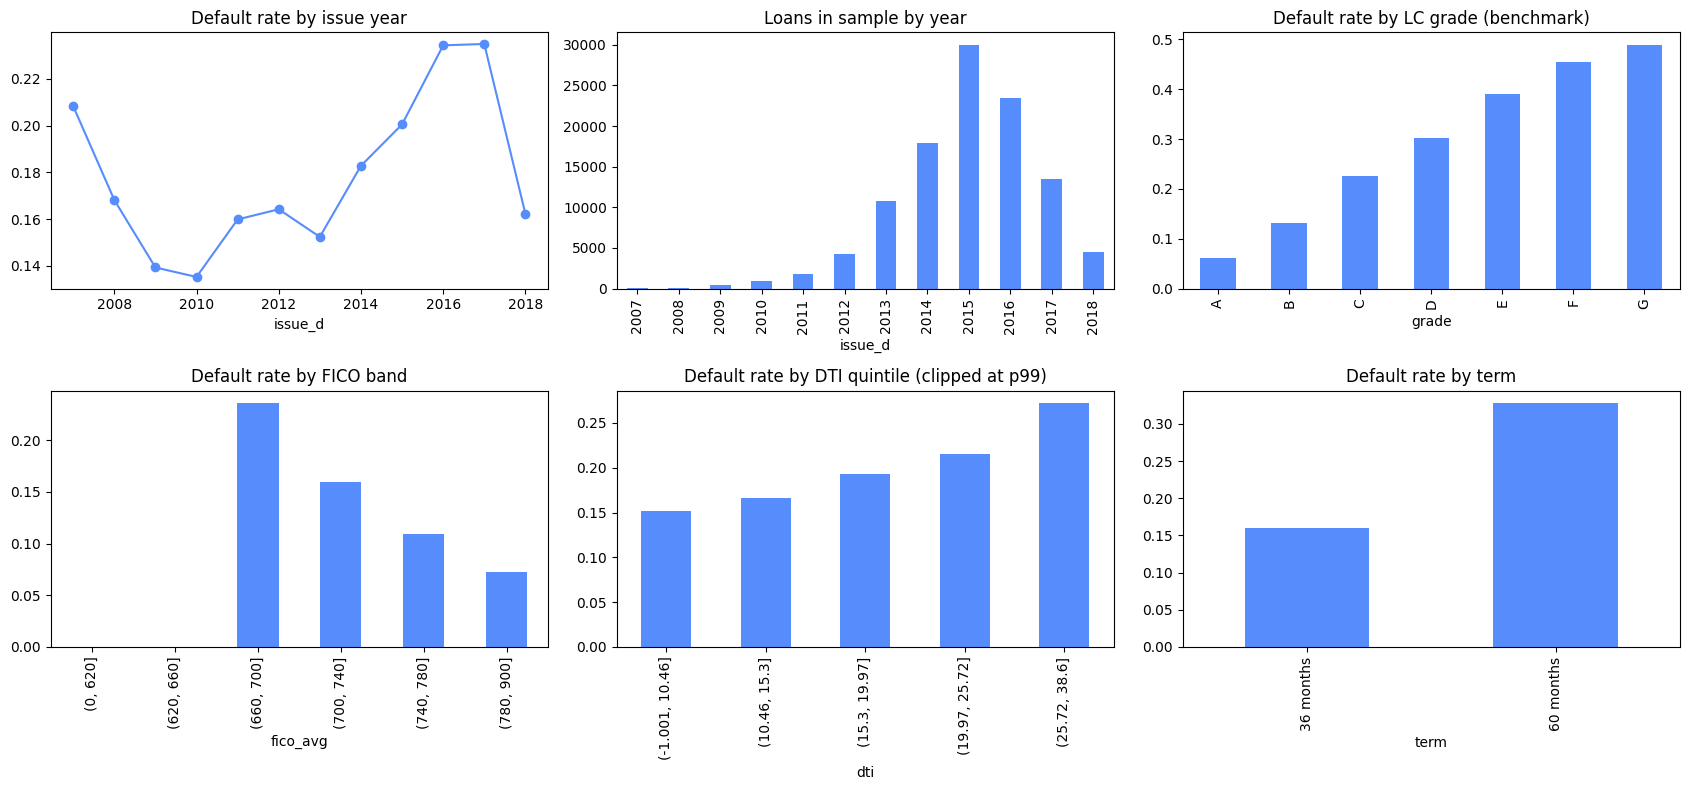

In [7]:
year = DF["issue_d"].dt.year
by_year = DF.groupby(year).agg(loans=("default", "size"), default_rate=("default", "mean"))
display(by_year.T.round(3))

fig, ax = plt.subplots(2, 3, figsize=(17, 8))
by_year["default_rate"].plot(marker="o", ax=ax[0, 0], title="Default rate by issue year")
by_year["loans"].plot(kind="bar", ax=ax[0, 1], title="Loans in sample by year")
DF.groupby("grade")["default"].mean().plot(kind="bar", ax=ax[0, 2], title="Default rate by LC grade (benchmark)")
DF.groupby(pd.cut(DF["fico_avg"], [0, 620, 660, 700, 740, 780, 900]), observed=False)["default"].mean() \
  .plot(kind="bar", ax=ax[1, 0], title="Default rate by FICO band")
dti_c = DF["dti"].clip(upper=DF["dti"].quantile(0.99))
DF.groupby(pd.qcut(dti_c, 5, duplicates="drop"), observed=False)["default"].mean() \
  .plot(kind="bar", ax=ax[1, 1], title="Default rate by DTI quintile (clipped at p99)")
DF.groupby("term")["default"].mean().plot(kind="bar", ax=ax[1, 2], title="Default rate by term")
plt.tight_layout(); plt.show()

In [8]:
cols_eda = available_numeric + available_categorical
miss = DF[cols_eda].isna().mean().sort_values(ascending=False)
print("Most-missing columns:"); display(miss.head(10).round(3).to_frame("missing_rate"))

probe = list(miss.index[:4])
print("Missing rate of those columns by issue year (systematic gaps => missingness is informative):")
display(DF.groupby(year)[probe].agg(lambda s: s.isna().mean()).round(2).T)

print("Other things worth checking:")
print("  corr(fico_avg, int_rate) =", round(DF["fico_avg"].corr(DF["int_rate"]), 3))
print("  DTI > 100 :", int((DF["dti"] > 100).sum()), "loans | annual_inc < 5000:", int((DF["annual_inc"] < 5000).sum()), "loans")
display(DF.groupby("purpose")["default"].agg(["count", "mean"]).sort_values("count", ascending=False).head(8).round(3))

Most-missing columns:


,missing_rate
mths_since_recent_inq,0.131
num_tl_120dpd_2m,0.087
emp_length,0.058
pct_tl_nvr_dlq,0.050
avg_cur_bal,0.050
num_rev_accts,0.050
num_actv_bc_tl,0.050
num_bc_tl,0.050
mo_sin_rcnt_tl,0.050
num_accts_ever_120_pd,0.050


Missing rate of those columns by issue year (systematic gaps => missingness is informative):


issue_d,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
mths_since_recent_inq,1.0,1.0,1.0,1.00,1.00,0.25,0.11,0.09,0.10,0.10,0.09,0.08
num_tl_120dpd_2m,1.0,1.0,1.0,1.00,1.00,0.52,0.00,0.04,0.05,0.05,0.05,0.03
emp_length,0.0,0.0,0.0,0.02,0.03,0.04,0.05,0.05,0.06,0.06,0.07,0.09
pct_tl_nvr_dlq,1.0,1.0,1.0,1.00,1.00,0.52,0.00,0.00,0.00,0.00,0.00,0.00


Other things worth checking:
  corr(fico_avg, int_rate) = -0.4
  DTI > 100 : 39 loans | annual_inc < 5000: 45 loans


,count,mean
purpose,,
debt_consolidation,62291,0.212
credit_card,23506,0.169
home_improvement,6978,0.183
other,6323,0.212
major_purchase,2400,0.183
medical,1271,0.202
small_business,1251,0.305
car,1180,0.142


### What the earlier run showed (from the pasted outputs; re-check against the numbers above)
- Default rate was **18.6% in the training period, 25.0% in validation, 21.5% in test**. The base rate moves with time, so a model calibrated on one period will be off in the next.
- Several credit-bureau columns were missing for roughly 5% of loans and one for 13%, which suggests missingness is not random -> numeric imputation below adds missing-indicator columns.
- A few DTI values were extreme (one over 300), so DTI is clipped only for plotting; tree models are robust to it and the linear baseline is scaled.

## 4. Feature engineering (only what the EDA motivates)

Two ratio features: credit-history length (a thin history is a classic risk marker) and loan-to-income (burden). Each must show a monotone relationship with default on its own, or it earns no place.

In [9]:
DF["credit_history_years"] = ((DF["issue_d"] - DF["earliest_cr_line"]).dt.days / 365.25).clip(lower=0)
DF["loan_to_income"] = DF["loan_amnt"] / DF["annual_inc"].replace(0, np.nan)

for f in ["credit_history_years", "loan_to_income"]:
    s = DF[f].clip(upper=DF[f].quantile(0.99))
    print(f)
    display(DF.groupby(pd.qcut(s, 5, duplicates="drop"), observed=False)["default"].mean().round(3).to_frame("default_rate").T)

ENGINEERED = ["fico_avg", "credit_history_years", "loan_to_income"]
MODEL_FEATURES = ([c for c in available_numeric if c not in ("fico_range_low", "fico_range_high")]
                  + available_categorical + ENGINEERED)

# Hard leakage guard: nothing from the benchmark / outcome / target groups may be a model input.
forbidden = set(BENCHMARK_FIELDS + OUTCOME_FIELDS + TARGET_FIELDS + ["default", "issue_d", "earliest_cr_line"])
assert not (set(MODEL_FEATURES) & forbidden), set(MODEL_FEATURES) & forbidden
print("Model features:", len(MODEL_FEATURES))

credit_history_years


credit_history_years,"(3.0, 10.494]","(10.494, 13.254]","(13.254, 16.498]","(16.498, 21.585]","(21.585, 39.75]"
default_rate,0.223,0.213,0.195,0.193,0.175


loan_to_income


loan_to_income,"(0.00026000000000000003, 0.108]","(0.108, 0.167]","(0.167, 0.231]","(0.231, 0.316]","(0.316, 0.5]"
default_rate,0.134,0.159,0.186,0.231,0.291


Model features: 56


## 5. Time-based split
Oldest 70% train, next 15% validation (model choices and calibration), newest 15% test (read once at the end).

In [10]:
n = len(DF); i1, i2 = int(n * 0.70), int(n * 0.85)
train_df, val_df, test_df = DF.iloc[:i1].copy(), DF.iloc[i1:i2].copy(), DF.iloc[i2:].copy()
for nm, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{nm:5s} n={len(d):>7,}  {d['issue_d'].min():%Y-%m} -> {d['issue_d'].max():%Y-%m}  default rate {d['default'].mean():.2%}")
y_train, y_val, y_test = train_df["default"], val_df["default"], test_df["default"]

numeric_features = [c for c in MODEL_FEATURES if pd.api.types.is_numeric_dtype(train_df[c])]
categorical_features = [c for c in MODEL_FEATURES if c not in numeric_features]
feature_cols = numeric_features + categorical_features
print(len(numeric_features), "numeric |", len(categorical_features), "categorical")

train n= 75,337  2007-07 -> 2016-04  default rate 18.60%
val   n= 16,144  2016-04 -> 2017-02  default rate 25.03%
test  n= 16,144  2017-02 -> 2018-12  default rate 21.49%
50 numeric | 6 categorical


## 6. Preprocessing and the evaluation helpers
Imputation and encoding are fitted inside a `Pipeline`, so they only ever learn from training data. Numeric imputation adds missing-indicator columns (motivated by section 3).

Metrics are chosen to answer the questions, not to fill a table:
- **ROC-AUC / PR-AUC**: ranking quality.
- **Lift @ top 10%**: default rate among the riskiest decile relative to the base rate (business-readable).
- **Brier and ECE**: are the probabilities usable as probabilities?
- **Precision @ 70% recall**: compares models at the *same* operating point, so one model is not penalised for a different cut-off.

In [11]:
def make_preprocess(num, cat):
    steps = []
    if num:
        steps.append(("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                                       ("sc", StandardScaler())]), num))
    if cat:
        steps.append(("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                                       ("oh", OneHotEncoder(handle_unknown="ignore", min_frequency=20))]), cat))
    return ColumnTransformer(steps)

def precision_at_recall(y, p, target=0.70):
    prec, rec, _ = precision_recall_curve(y, p)
    ok = prec[rec >= target]
    return float(ok.max()) if len(ok) else np.nan

def top_decile_lift(y, p, frac=0.10):
    y, p = np.asarray(y), np.asarray(p)
    k = max(int(len(y) * frac), 1)
    return float(y[np.argsort(-p)[:k]].mean() / y.mean())

def calib_table(y, p, bins=10):
    d = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p)})
    d["bin"] = pd.qcut(d["p"], bins, duplicates="drop")
    g = d.groupby("bin", observed=False).agg(mean_pred=("p", "mean"), observed=("y", "mean"), n=("y", "size")).reset_index(drop=True)
    g["gap"] = g["mean_pred"] - g["observed"]
    return g

def ece(y, p, bins=10):
    g = calib_table(y, p, bins)
    return float((g["n"] * g["gap"].abs()).sum() / g["n"].sum())

def score_row(name, y, p):
    return {"model": name,
            "ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "Brier": brier_score_loss(y, p), "ECE": ece(y, p),
            "Lift@10%": top_decile_lift(y, p), "Prec@70%rec": precision_at_recall(y, p)}

def score_table(probs, y):
    return pd.DataFrame([score_row(k, y, v) for k, v in probs.items()]).set_index("model").round(4)

def paired_auc_diff(y, pa, pb, n_boot=N_BOOT, seed=0):
    """AUC(a) - AUC(b) with a paired bootstrap 95% interval (same resampled loans for both)."""
    y, pa, pb = np.asarray(y), np.asarray(pa), np.asarray(pb)
    rng = np.random.default_rng(seed); diffs = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() == y[i].max():
            continue
        diffs.append(roc_auc_score(y[i], pa[i]) - roc_auc_score(y[i], pb[i]))
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    return roc_auc_score(y, pa) - roc_auc_score(y, pb), lo, hi

VAL, TEST, FITTED = {}, {}, {}
def fit_store(name, pipe, num, cat):
    cols = num + cat
    pipe.fit(train_df[cols], y_train)
    VAL[name]  = pipe.predict_proba(val_df[cols])[:, 1]
    TEST[name] = pipe.predict_proba(test_df[cols])[:, 1]
    FITTED[name] = (pipe, cols)

## 7. Baselines, including LendingClub's own assessment
Three simple references, all fitted on the training period:
- **LC pricing**: `sub_grade` + `int_rate`. This is what the incumbent already knew when it priced the loan. It is the bar for "does our model add anything?".
- **FICO only**: the single strongest raw signal.
- **Logistic, application features**: the transparent baseline for the full feature set.

In [12]:
def logit_pipe(num, cat):
    return Pipeline([("prep", make_preprocess(num, cat)),
                     ("model", LogisticRegression(max_iter=3000, C=1.0))])

LC_NUM, LC_CAT = ["int_rate"], ["sub_grade"]
fit_store("LC pricing (sub_grade+int_rate)", logit_pipe(LC_NUM, LC_CAT), LC_NUM, LC_CAT)
fit_store("FICO only", logit_pipe(["fico_avg"], []), ["fico_avg"], [])
fit_store("Logistic: application", logit_pipe(numeric_features, categorical_features), numeric_features, categorical_features)

base_rate = y_train.mean()
print("Validation (model choices are made here):")
val_tbl = score_table(VAL, y_val)
val_tbl.loc["(constant = train base rate)", "Brier"] = round(brier_score_loss(y_val, np.full(len(y_val), base_rate)), 4)
display(val_tbl)

Validation (model choices are made here):


,ROC-AUC,PR-AUC,Brier,ECE,Lift@10%,Prec@70%rec
model,,,,,,
LC pricing (sub_grade+int_rate),0.6760,0.3901,0.1787,0.0632,1.8837,0.3367
FICO only,0.5951,0.3047,0.1878,0.0643,1.3540,0.2920
Logistic: application,0.6957,0.4229,0.1756,0.0656,2.0891,0.3601
(constant = train base rate),NaN,NaN,0.1918,NaN,NaN,NaN


## 8. A stronger model: tuned XGBoost
Random search with `TimeSeriesSplit` inside the training period, so every fold validates on loans newer than its training loans. Scoring is PR-AUC because defaults are the minority class.

In [13]:
xgb_pipe = Pipeline([
    ("prep", make_preprocess(numeric_features, categorical_features)),
    ("model", XGBClassifier(objective="binary:logistic", eval_metric="logloss",
                            tree_method="hist", random_state=RANDOM_STATE, n_jobs=-1)),
])
param_dist = {
    "model__n_estimators": [250, 400, 600],
    "model__max_depth": [3, 4, 5, 6],
    "model__learning_rate": [0.02, 0.04, 0.07, 0.1],
    "model__subsample": [0.7, 0.85, 1.0],
    "model__colsample_bytree": [0.7, 0.85, 1.0],
    "model__min_child_weight": [1, 3, 6, 10],
    "model__reg_alpha": [0, 0.05, 0.2],
    "model__reg_lambda": [1, 2, 5],
}
search = RandomizedSearchCV(xgb_pipe, param_dist, n_iter=N_ITER, scoring="average_precision",
                            cv=TimeSeriesSplit(n_splits=3), random_state=RANDOM_STATE,
                            n_jobs=-1, verbose=1, refit=True)
search.fit(train_df[feature_cols], y_train)
best_xgb = search.best_estimator_
print("Best CV PR-AUC:", round(search.best_score_, 4))
print(search.best_params_)

VAL["XGBoost (raw)"]  = best_xgb.predict_proba(val_df[feature_cols])[:, 1]
TEST["XGBoost (raw)"] = best_xgb.predict_proba(test_df[feature_cols])[:, 1]
FITTED["XGBoost (raw)"] = (best_xgb, feature_cols)
display(score_table({k: VAL[k] for k in ["Logistic: application", "XGBoost (raw)"]}, y_val))

Fitting 3 folds for each of 18 candidates, totalling 54 fits
Best CV PR-AUC: 0.3874
{'model__subsample': 0.85, 'model__reg_lambda': 5, 'model__reg_alpha': 0.2, 'model__n_estimators': 250, 'model__min_child_weight': 10, 'model__max_depth': 5, 'model__learning_rate': 0.02, 'model__colsample_bytree': 1.0}


,ROC-AUC,PR-AUC,Brier,ECE,Lift@10%,Prec@70%rec
model,,,,,,
Logistic: application,0.6957,0.4229,0.1756,0.0656,2.0891,0.3601
XGBoost (raw),0.6939,0.4267,0.1759,0.0671,2.0470,0.3578


## 9. Does our estimate add anything beyond LendingClub's own pricing?
Two combined models answer this: the same application features **plus** `sub_grade`/`int_rate`.
- If adding our features to LC's pricing helps, our information is not already priced in.
- If adding LC's pricing to our features helps, LC saw something we cannot (e.g. its own underwriting inputs).

Differences are reported with paired-bootstrap 95% intervals on the **test** period. An interval that includes 0 means "no demonstrated difference".

In [14]:
best_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
xgb_plus = Pipeline([
    ("prep", make_preprocess(numeric_features + LC_NUM, categorical_features + LC_CAT)),
    ("model", XGBClassifier(objective="binary:logistic", eval_metric="logloss", tree_method="hist",
                            random_state=RANDOM_STATE, n_jobs=-1, **best_params)),
])
fit_store("XGBoost: application + LC pricing", xgb_plus, numeric_features + LC_NUM, categorical_features + LC_CAT)
fit_store("Logistic: application + LC pricing", logit_pipe(numeric_features + LC_NUM, categorical_features + LC_CAT),
          numeric_features + LC_NUM, categorical_features + LC_CAT)

comparisons = [
    ("XGBoost (raw)",                     "Logistic: application",              "Does a stronger model beat the simple one?"),
    ("Logistic: application",             "LC pricing (sub_grade+int_rate)",    "Do our features alone match LC's pricing?"),
    ("XGBoost (raw)",                     "LC pricing (sub_grade+int_rate)",    "Does our best model beat LC's pricing?"),
    ("XGBoost: application + LC pricing", "LC pricing (sub_grade+int_rate)",    "Do our features add to LC's pricing?"),
    ("XGBoost: application + LC pricing", "XGBoost (raw)",                      "Does LC's pricing add to our features?"),
]
rows = []
for a, b, q in comparisons:
    d, lo, hi = paired_auc_diff(y_test, TEST[a], TEST[b])
    rows.append({"question": q, "A": a, "B": b, "AUC(A)-AUC(B)": d, "95% CI low": lo, "95% CI high": hi,
                 "interval excludes 0": (lo > 0) or (hi < 0)})
display(pd.DataFrame(rows).round(4))

,question,A,B,AUC(A)-AUC(B),95% CI low,95% CI high,interval excludes 0
0,Does a stronger model beat the simple one?,XGBoost (raw),Logistic: application,0.0029,-0.0014,0.0073,False
1,Do our features alone match LC's pricing?,Logistic: application,LC pricing (sub_grade+int_rate),0.0039,-0.0051,0.0126,False
2,Does our best model beat LC's pricing?,XGBoost (raw),LC pricing (sub_grade+int_rate),0.0068,-0.0020,0.0153,False
3,Do our features add to LC's pricing?,XGBoost: application + LC pricing,LC pricing (sub_grade+int_rate),0.0188,0.0133,0.0244,True
4,Does LC's pricing add to our features?,XGBoost: application + LC pricing,XGBoost (raw),0.0120,0.0075,0.0166,True


## 10. Calibration
For pricing, "0.18" has to mean roughly 18 in 100 loans default. We calibrate XGBoost with Platt scaling on the **validation** period and judge it on **test**. Because the base rate moved between periods (section 5), expect calibration-in-the-large to be imperfect, and look at *where* it breaks.

Calibration-in-the-large (mean predicted vs observed default rate):
  Logistic: application    val 0.185 vs 0.250 | test 0.177 vs 0.215
  XGBoost (raw)            val 0.183 vs 0.250 | test 0.179 vs 0.215
  XGBoost (calibrated)     val 0.250 vs 0.250 | test 0.244 vs 0.215

TEST period (read once):


,ROC-AUC,PR-AUC,Brier,ECE,Lift@10%,Prec@70%rec
model,,,,,,
LC pricing (sub_grade+int_rate),0.6760,0.3355,0.1595,0.0346,1.8165,0.3004
FICO only,0.5963,0.2623,0.1669,0.0394,1.3437,0.2583
Logistic: application,0.6800,0.3540,0.1600,0.0418,2.0789,0.3049
XGBoost (raw),0.6828,0.3601,0.1583,0.0363,2.0732,0.2989
XGBoost (calibrated),0.6828,0.3601,0.1583,0.0318,2.0732,0.2989
Logistic: application + LC pricing,0.6923,0.3612,0.1581,0.0379,2.0357,0.3129
XGBoost: application + LC pricing,0.6948,0.3704,0.1561,0.0278,2.0876,0.3099


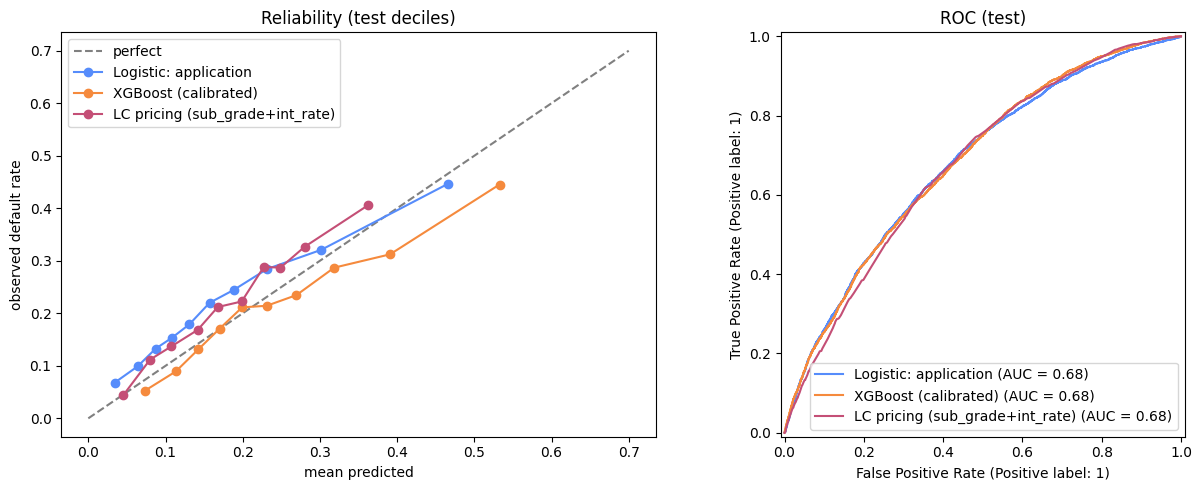

Decile table, calibrated XGBoost (gap = predicted - observed; positive = overstated risk):


,mean_pred,observed,n,gap
0,0.073,0.053,1615,0.021
1,0.113,0.089,1614,0.024
2,0.143,0.131,1614,0.011
3,0.170,0.171,1615,-0.001
4,0.199,0.211,1614,-0.012
5,0.231,0.214,1614,0.017
6,0.270,0.235,1615,0.035
7,0.318,0.287,1614,0.032
8,0.391,0.312,1614,0.079
9,0.533,0.445,1615,0.087


In [15]:
def logit_t(p, eps=1e-6):
    p = np.clip(np.asarray(p), eps, 1 - eps)
    return np.log(p / (1 - p)).reshape(-1, 1)

platt = LogisticRegression().fit(logit_t(VAL["XGBoost (raw)"]), y_val)
VAL["XGBoost (calibrated)"]  = platt.predict_proba(logit_t(VAL["XGBoost (raw)"]))[:, 1]
TEST["XGBoost (calibrated)"] = platt.predict_proba(logit_t(TEST["XGBoost (raw)"]))[:, 1]

print("Calibration-in-the-large (mean predicted vs observed default rate):")
for nm in ["Logistic: application", "XGBoost (raw)", "XGBoost (calibrated)"]:
    print(f"  {nm:24s} val {VAL[nm].mean():.3f} vs {y_val.mean():.3f} | test {TEST[nm].mean():.3f} vs {y_test.mean():.3f}")

final_models = ["LC pricing (sub_grade+int_rate)", "FICO only", "Logistic: application",
                "XGBoost (raw)", "XGBoost (calibrated)",
                "Logistic: application + LC pricing", "XGBoost: application + LC pricing"]
print("\nTEST period (read once):")
display(score_table({k: TEST[k] for k in final_models}, y_test))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].plot([0, 0.7], [0, 0.7], "--", color="grey", label="perfect")
for nm in ["Logistic: application", "XGBoost (calibrated)", "LC pricing (sub_grade+int_rate)"]:
    g = calib_table(y_test, TEST[nm]); ax[0].plot(g["mean_pred"], g["observed"], marker="o", label=nm)
ax[0].set_xlabel("mean predicted"); ax[0].set_ylabel("observed default rate"); ax[0].set_title("Reliability (test deciles)"); ax[0].legend()
for nm in ["Logistic: application", "XGBoost (calibrated)", "LC pricing (sub_grade+int_rate)"]:
    RocCurveDisplay.from_predictions(y_test, TEST[nm], name=nm, ax=ax[1])
ax[1].set_title("ROC (test)")
plt.tight_layout(); plt.show()
print("Decile table, calibrated XGBoost (gap = predicted - observed; positive = overstated risk):")
display(calib_table(y_test, TEST["XGBoost (calibrated)"]).round(3))

## 11. Operating point, compared fairly
A hard yes/no needs a threshold. To avoid comparing models at different cut-offs, each model gets the threshold chosen **on validation** to catch at least 70% of defaults, and is then judged on test: how many loans it flags, how precise the flags are, and the recall actually achieved.

In [16]:
def threshold_for_recall(y, p, target=0.70):
    prec, rec, thr = precision_recall_curve(y, p)
    ok = np.where(rec[:-1] >= target)[0]
    return float(thr[ok].max()) if len(ok) else float(thr.min())

rows = []
for nm in ["LC pricing (sub_grade+int_rate)", "Logistic: application", "XGBoost (calibrated)", "XGBoost: application + LC pricing"]:
    t = threshold_for_recall(y_val, VAL[nm])
    flag = TEST[nm] >= t
    tp = int((flag & (y_test.values == 1)).sum())
    rows.append({"model": nm, "val-chosen threshold": t, "share flagged (test)": flag.mean(),
                 "precision (test)": tp / max(flag.sum(), 1), "recall (test)": tp / y_test.sum()})
display(pd.DataFrame(rows).set_index("model").round(3))
print("Test base rate:", round(y_test.mean(), 3), "(precision is only informative relative to this)")

,val-chosen threshold,share flagged (test),precision (test),recall (test)
model,,,,
LC pricing (sub_grade+int_rate),0.175,0.539,0.297,0.746
Logistic: application,0.158,0.445,0.314,0.650
XGBoost (calibrated),0.226,0.464,0.306,0.661
XGBoost: application + LC pricing,0.166,0.469,0.313,0.683


Test base rate: 0.215 (precision is only informative relative to this)


## 12. Explainability
Permutation importance on a test sample: how much PR-AUC drops when one feature is shuffled. Model-agnostic and easy to defend.

,feature,importance
50,term,0.0460
47,fico_avg,0.0189
49,loan_to_income,0.0102
45,total_bc_limit,0.0074
24,mort_acc,0.0058
43,tot_hi_cred_lim,0.0055
52,home_ownership,0.0053
21,mo_sin_old_rev_tl_op,0.0049
16,avg_cur_bal,0.0044
25,mths_since_recent_inq,0.0043


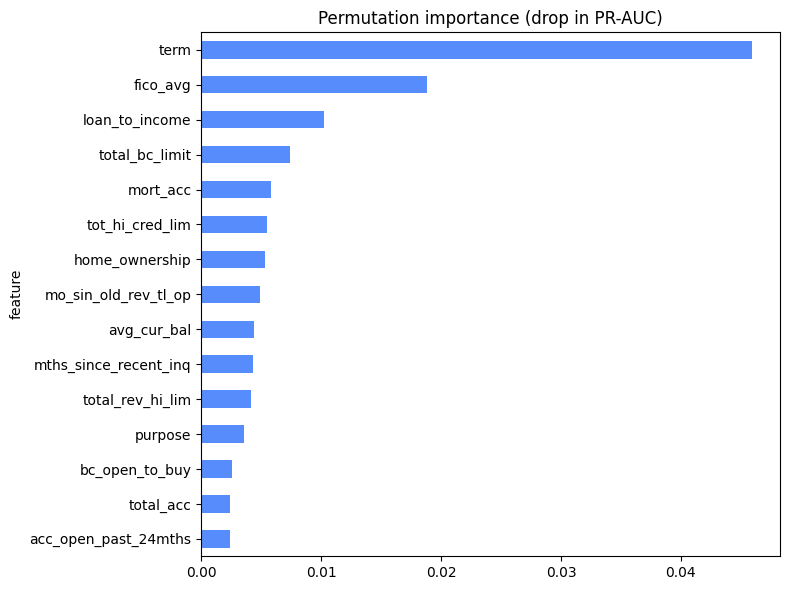

In [17]:
samp = test_df.sample(min(5000, len(test_df)), random_state=RANDOM_STATE)
perm = permutation_importance(best_xgb, samp[feature_cols], samp["default"], scoring="average_precision",
                              n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"feature": feature_cols, "importance": perm.importances_mean}).sort_values("importance", ascending=False)
display(imp.head(15).round(4))
imp.head(15).sort_values("importance").plot(kind="barh", x="feature", y="importance", legend=False, figsize=(8, 6),
                                            title="Permutation importance (drop in PR-AUC)")
plt.tight_layout(); plt.show()

## 13. Pricing back-test: measured loss severity, assumed funding cost and margin

Expected loss rate = PD x LGD. Suggested rate = funding cost + operating margin + expected loss rate.

| Input | Source |
|---|---|
| PD | calibrated model (test period) |
| **LGD** | **measured**: share of funded principal not recovered on charged-off loans in the training period (post-origination fields used here only) |
| Funding cost, operating margin | **assumptions**, varied in a sensitivity grid below |

Simplifications to keep in mind: no interest earned before default, no prepayment, no time value, no collection costs.

Measured LGD on charged-off loans (train period): gross 67.2%, net of recoveries 59.0%
By predicted-risk decile (does predicted loss track realized loss?):


,loans,avg LC rate,avg suggested rate,avg predicted PD,realized default,predicted loss rate,realized loss rate
decile,,,,,,,
1,1615.0,0.077,0.108,0.073,0.053,0.043,0.043
2,1614.0,0.100,0.132,0.113,0.089,0.067,0.072
3,1614.0,0.115,0.149,0.143,0.131,0.084,0.107
4,1615.0,0.125,0.165,0.170,0.171,0.100,0.140
5,1614.0,0.134,0.183,0.199,0.211,0.118,0.165
6,1614.0,0.141,0.201,0.231,0.214,0.136,0.162
7,1615.0,0.151,0.224,0.270,0.235,0.159,0.177
8,1614.0,0.160,0.253,0.318,0.287,0.188,0.227
9,1614.0,0.176,0.296,0.391,0.312,0.231,0.262


By LendingClub grade (what LC charged vs what loans actually lost):


,loans,avg LC rate,avg suggested rate,avg predicted PD,realized default,predicted loss rate,realized loss rate,LC rate minus realized loss
grade,,,,,,,,
A,2894.0,0.070,0.134,0.117,0.070,0.069,0.060,0.010
B,4450.0,0.107,0.181,0.198,0.150,0.116,0.117,-0.011
C,4903.0,0.144,0.227,0.276,0.254,0.163,0.218,-0.074
D,2516.0,0.190,0.256,0.327,0.313,0.193,0.270,-0.080
E,917.0,0.250,0.282,0.375,0.388,0.221,0.349,-0.099
F,283.0,0.298,0.309,0.425,0.470,0.251,0.397,-0.099
G,181.0,0.309,0.326,0.462,0.436,0.273,0.374,-0.065


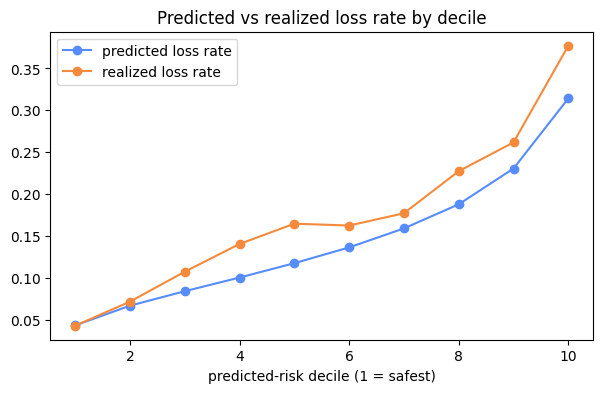

In [18]:
def loss_amounts(d):
    funded = d["funded_amnt"].fillna(d["loan_amnt"])
    gross = (funded - d["total_rec_prncp"].fillna(0)).clip(lower=0)
    net = (gross - d["recoveries"].fillna(0)).clip(lower=0)
    return np.where(d["default"] == 1, gross, 0.0), np.where(d["default"] == 1, net, 0.0), funded

co = train_df[train_df["default"] == 1]
g_loss, n_loss, f = loss_amounts(co)
LGD_GROSS = g_loss.sum() / f.sum()
LGD_NET = n_loss.sum() / f.sum()
print(f"Measured LGD on charged-off loans (train period): gross {LGD_GROSS:.1%}, net of recoveries {LGD_NET:.1%}")
LGD = float(LGD_NET)

FUNDING_COST = 0.04        # ASSUMPTION
OPERATING_MARGIN = 0.025   # ASSUMPTION
def suggested_rate(pd_prob, lgd=None, funding=None, margin=None):
    lgd = LGD if lgd is None else lgd
    funding = FUNDING_COST if funding is None else funding
    margin = OPERATING_MARGIN if margin is None else margin
    return np.clip(funding + margin + np.asarray(pd_prob) * lgd, 0, 0.40)

pr = test_df[["loan_amnt", "funded_amnt", "int_rate", "grade", "default"]].copy()
_, net_loss_test, funded_test = loss_amounts(test_df)
pr["funded"] = np.asarray(funded_test); pr["loss"] = net_loss_test
pr["pd"] = TEST["XGBoost (calibrated)"]
pr["suggested"] = suggested_rate(pr["pd"])
pr["lc_rate"] = pd.to_numeric(pr["int_rate"], errors="coerce") / 100

def summarize(g):
    return pd.Series({"loans": len(g), "avg LC rate": g["lc_rate"].mean(), "avg suggested rate": g["suggested"].mean(),
                      "avg predicted PD": g["pd"].mean(), "realized default": g["default"].mean(),
                      "predicted loss rate": g["pd"].mean() * LGD, "realized loss rate": g["loss"].sum() / g["funded"].sum()})

print("By predicted-risk decile (does predicted loss track realized loss?):")
pr["decile"] = pd.qcut(pr["pd"], 10, labels=False, duplicates="drop") + 1
dec = pr.groupby("decile").apply(summarize)
display(dec.round(3))
print("By LendingClub grade (what LC charged vs what loans actually lost):")
by_grade = pr.groupby("grade").apply(summarize)
by_grade["LC rate minus realized loss"] = by_grade["avg LC rate"] - by_grade["realized loss rate"]
display(by_grade.round(3))

ax = dec[["predicted loss rate", "realized loss rate"]].plot(marker="o", figsize=(7, 4), title="Predicted vs realized loss rate by decile")
ax.set_xlabel("predicted-risk decile (1 = safest)"); plt.show()

In [19]:
# Sensitivity: how much of the suggested rate is the model and how much is the assumptions?
lgds = [LGD - 0.10, LGD, LGD + 0.10]
fundings = [0.03, 0.04, 0.05]
grid = pd.DataFrame({f"funding {fc:.0%}": {f"LGD {l:.0%}": np.median(suggested_rate(pr["pd"], lgd=l, funding=fc)) for l in lgds}
                     for fc in fundings})
print("Median suggested rate under different assumptions (margin fixed at", f"{OPERATING_MARGIN:.1%}):")
display((grid * 100).round(1))
print("Spread of the model's own contribution (PD x LGD) across test loans, p10 / p50 / p90:",
      np.percentile(pr["pd"] * LGD * 100, [10, 50, 90]).round(1), "percentage points")

Median suggested rate under different assumptions (margin fixed at 2.5%):


,funding 3%,funding 4%,funding 5%
LGD 49%,16.0,17.0,18.0
LGD 59%,18.1,19.1,20.1
LGD 69%,20.3,21.3,22.3


Spread of the model's own contribution (PD x LGD) across test loans, p10 / p50 / p90: [ 5.7 12.6 26.1] percentage points


## 14. Save artifacts (and optional demo app)

In [20]:
ARTIFACT_DIR = os.environ.get("LC_ARTIFACT_DIR", "lending_artifacts")
os.makedirs(ARTIFACT_DIR, exist_ok=True)
joblib.dump(best_xgb, f"{ARTIFACT_DIR}/xgb_risk_model.joblib")
joblib.dump(platt, f"{ARTIFACT_DIR}/platt_calibrator.joblib")

def make_defaults(frame, feats):
    out = {}
    for c in feats:
        s = frame[c]
        if pd.api.types.is_numeric_dtype(s):
            out[c] = None if pd.isna(s.median()) else float(s.median())
        else:
            m = s.mode(dropna=True); out[c] = None if len(m) == 0 else str(m.iloc[0])
    return out

metadata = {"feature_cols": feature_cols, "numeric_features": numeric_features,
            "categorical_features": categorical_features, "defaults": make_defaults(train_df, feature_cols),
            "LGD_measured_net": LGD, "FUNDING_COST_assumed": FUNDING_COST, "OPERATING_MARGIN_assumed": OPERATING_MARGIN}
with open(f"{ARTIFACT_DIR}/metadata.json", "w") as fh:
    json.dump(metadata, fh, indent=2)
print("Saved to", ARTIFACT_DIR)

Saved to lending_artifacts


In [22]:
LAUNCH_APP = False   # set True to start the Gradio demo
if LAUNCH_APP:
    import gradio as gr
    UI = [c for c in ["loan_amnt", "annual_inc", "dti", "fico_avg", "revol_util", "inq_last_6mths",
                      "delinq_2yrs", "open_acc", "term", "home_ownership", "purpose"] if c in feature_cols]

    def score_application(*vals):
        row = metadata["defaults"].copy()
        row.update(dict(zip(UI, vals)))
        raw = best_xgb.predict_proba(pd.DataFrame([row], columns=feature_cols))[:, 1]
        p = float(platt.predict_proba(logit_t(raw))[:, 1][0])
        return {"default_probability": round(p, 4),
                "expected_loss_rate": round(p * LGD, 4),
                "simulated_suggested_rate": round(float(suggested_rate(p)), 4)}

    comps = []
    for c in UI:
        if c in categorical_features:
            ch = sorted(train_df[c].dropna().astype(str).unique())[:50]
            comps.append(gr.Dropdown(choices=ch, value=str(metadata["defaults"][c]), label=c))
        else:
            comps.append(gr.Number(value=metadata["defaults"][c], label=c))
    gr.Interface(fn=score_application, inputs=comps, outputs=gr.JSON(label="Risk & pricing"),
                 title="Risk-based pricing simulator (educational)").launch(share=False)

## 15. Conclusions (write these from the outputs above, not before)

Answer each in one or two sentences with the number that supports it:

1. **Ranking power from application-time data alone:** ROC-AUC / lift@10% on test for the logistic baseline.
2. **Stronger model vs simple model:** the AUC difference and its 95% interval from section 9. If the interval includes 0, say "no demonstrated gain".
3. **Beyond LendingClub's own pricing:** the "application + LC pricing" vs "LC pricing" interval. This is the headline result for whether the model is useful to a lender who already has grades.
4. **Are the probabilities trustworthy:** calibration-in-the-large on test, ECE, and which deciles are over/understated (section 10). Tie it to the shift in base rate across periods.
5. **Pricing:** the back-test table (predicted vs realized loss by decile), the measured LGD, and how much of the suggested rate moves with funding/margin assumptions rather than the model.
6. **Limitations to state plainly:** survivorship/censoring in the newest cohort, no interest-income or prepayment in the pricing rule, a single dataset from one platform, and the one test period.

From the earlier run (for reference only; re-check): XGBoost test ROC-AUC 0.689 vs logistic 0.680. Its F1 of 0.43 vs 0.10 largely reflected a lower cut-off, which section 11 now controls for.

### Rubric map
Problem & data pipeline: sections 1-5 | EDA & features: 3-4 | Baseline: 7 | Advanced tuned model: 8 | Comparison & diagnostics (ROC/PR, calibration, error/threshold analysis, importance): 9-12 | Business use & deployment artifacts: 13-14.